In [1]:
import sys
from pathlib import Path

# Add parent directory to path so forestgap can be imported
sys.path.insert(0, str(Path('.').resolve().parent))

In [2]:
from forestgap import SparseProximityMixin, with_sparse_proximity, _RotationForestApplyAdapter
from aeon.classification.sklearn import RotationForestClassifier
from aeon.regression.sklearn import RotationForestRegressor

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.manifold import MDS
from phate import PHATE

In [3]:
data_name = 'treeData'

data = pd.read_csv("..\datasets\\" + data_name + ".csv")

y = data.iloc[:, 0]
X = data.iloc[:, 1:]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

train_order = np.argsort(y_train.to_numpy())
test_order = np.argsort(y_test.to_numpy())

X_train = X_train.iloc[train_order].reset_index(drop=True)
y_train = y_train.iloc[train_order].reset_index(drop=True)

X_test = X_test.iloc[test_order].reset_index(drop=True)
y_test = y_test.iloc[test_order].reset_index(drop=True)

In [5]:
rf_class = with_sparse_proximity(RotationForestClassifier)
# rf_class = with_sparse_proximity(RandomForestClassifier)
rf = rf_class(n_estimators = 100, random_state = 0, prox_method = 'rfgap')

In [6]:
rf.fit(X_train, y_train)
score = rf.score(X_test, y_test)
print('Test Score: ', score)
print('OOB Score: ', rf.oob_score_)

c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Test Score:  0.9236111111111112
OOB Score:  0.941468253968254


In [7]:
prox = rf.get_proximities().toarray()
prox_symmetric = prox + prox.T - np.diag(prox.diagonal())

prox_scaled = (prox_symmetric - prox_symmetric.min()) / (prox_symmetric.max() - prox_symmetric.min())

In [8]:
# mds = MDS(n_components = 2, dissimilarity = 'precomputed', random_state = 0)
# emb = mds.fit_transform(1 - prox_scaled)

phate_op = PHATE(n_components= 2, knn_dist = 'precomputed_affinity')
emb = phate_op.fit_transform(prox_scaled)

Calculating PHATE...
  Running PHATE on precomputed affinity matrix with 1008 observations.
  Calculating graph and diffusion operator...
  Calculated graph and diffusion operator in 0.01 seconds.
  Calculating optimal t...


c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\graphtools\base.py:554: RuntimeWarning: K should have a non-zero diagonal
  warnings.warn("K should have a non-zero diagonal", RuntimeWarning)


    Automatically selected t = 2
  Calculated optimal t in 0.64 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.02 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 0.55 seconds.
Calculated PHATE in 1.23 seconds.


<Axes: >

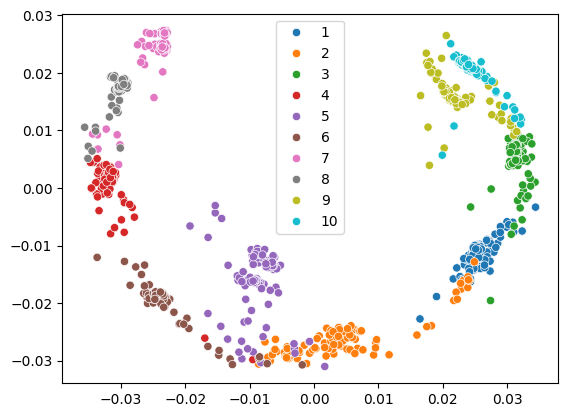

In [9]:
sns.scatterplot(x = emb[:, 0], y = emb[:, 1], hue = pd.Categorical(y_train.iloc[:]))

<Axes: >

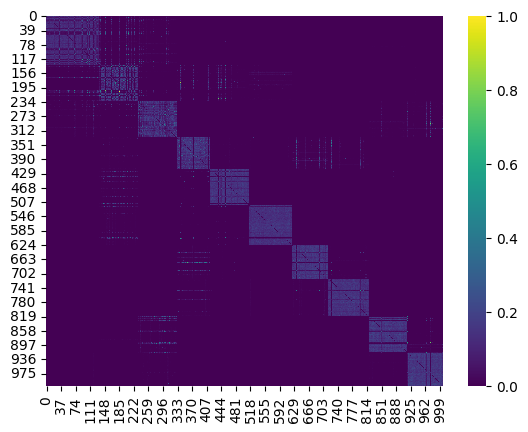

In [10]:
sns.heatmap(prox_scaled, cmap='viridis')

In [11]:
y_hot = pd.get_dummies(y_train).to_numpy()

In [12]:
np.argmax(prox @ y_hot, axis=1)

array([0, 0, 0, ..., 9, 9, 9], dtype=int64)

In [13]:
# Row-wise sum of proximities grouped by class (using training labels)
class_labels = np.sort(y_train.unique())

prox_row_sum_by_class = pd.DataFrame(
    prox @ y_hot.astype(np.float32),
    columns=class_labels
)

prox_row_sum_by_class.to_csv('prox_row_sum_by_class.csv', index=False)

In [14]:
rf.oob_decision_function_.max(axis = 1).argmin()

250